# Limiar × Aprendizado de Máquina na detecção de quedas: quanto cada um perde ao trocar de base?

**Projeto Mova (UNAMA).** Estudo 100% offline, só com bases públicas. Não tem app nem coleta com voluntários.

### Pergunta de pesquisa
> Quando um detector de quedas é ajustado ou treinado numa base de dados e testado em outra (*cross-dataset*), os **algoritmos de limiar** perdem desempenho **tanto quanto** um **modelo leve de aprendizado de máquina** (TinyML)?

### Hipóteses
- **H1:** o ML vai melhor *dentro* da base de treino, mas cai **mais** ao mudar de base. Os limiares começam piores e são mais estáveis.
- **H0:** a queda de desempenho (Δ) é igual nos dois tipos de método.
- **H1-alternativa:** o ML continua melhor e cai menos. É o que Duan et al. (2026) afirmam: queda de cerca de 1% da KFall para a SisFall.

### Métodos comparados
| Família | Método | Referência | Fonte da implementação |
|---|---|---|---|
| Limiar | Kangas, variante 2 | Kangas et al. 2008, *Gait & Posture* 28(2) | Parâmetros do Bagalà 2012 e do porte aberto "Guardian" |
| Limiar | Bourke3 (velocidade + impacto + postura) | Bourke et al. 2010, *J. Biomech.* 43(15) | Parâmetros do Bagalà et al. 2012, *PLoS ONE* 7(5):e37062 |
| Limiar | PIPTO | Moutsis et al. 2023, *Sensors* 23(18):7951 | **Código original dos autores**, baixado do GitHub na execução |
| ML (TinyML) | CNN-LSTM, 21.434 parâmetros | Duan et al. 2026, *Int. J. Technology* 17(3):919-935 | Reimplementada a partir do texto; não há código público |

### Bases e direções testadas
| Base | Sensor e posição | Taxa | Participantes | Acesso |
|---|---|---|---|---|
| **SisFall** (Sucerquia et al. 2017) | dispositivo próprio **na cintura** | 200 Hz | 23 jovens + 15 idosos (idosos só ADL, exceto o SE06) | espelho no GitHub |
| **MobiFall v2.0** (Vavoulas et al. 2014) | **smartphone no bolso da calça** (Samsung Galaxy S3) | ~90 Hz, irregular | 24 adultos de 22 a 47 anos; ADL de só 9 deles | espelho no GitHub |
| KFall (Yu et al. 2021) | IMU na lombar | 100 Hz | 32 jovens | sob pedido (opcional) |

- **Direções avaliadas:**
  - **SisFall → MobiFall** (cintura → celular no bolso). É a direção que interessa ao Mova.
  - **MobiFall → SisFall** (bolso → cintura).
- **Quando a KFall estiver disponível:** acrescente `('KFall', 'SisFall')` para reproduzir exatamente o protocolo de Duan et al.

### Desenho experimental
1. **Dentro da base de treino:**
   - limiares com os parâmetros publicados;
   - limiares reajustados, com validação cruzada por sujeito;
   - CNN-LSTM com validação cruzada por sujeito.
2. **Entre bases:** nada é reajustado nem retreinado; o mesmo detector é aplicado na outra base.
3. **Métrica principal:** **Δ = desempenho na base de treino − desempenho na base de teste**, com IC 95% por *bootstrap* de sujeitos.
4. **Avaliação por tentativa (arquivo)**, igual para todos. Também calculamos os **alarmes falsos por hora** de atividade normal.

In [1]:
# Dependências (no Colab só falta o openpyxl; localmente, descomente a linha abaixo)
# !pip install numpy scipy pandas matplotlib openpyxl tensorflow

## 1. Configuração
As escolhas que **não estão nos artigos** estão marcadas com `SUPOSIÇÃO`; declarem todas na seção de Métodos do artigo.

In [2]:
from pathlib import Path
import os, re, sys, math, json, time, subprocess, warnings
from dataclasses import dataclass
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import resample_poly, butter, lfilter, lfilter_zi

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

MODO_DEMO = False        # True = dados sintéticos só para testar o código

BASE_DIR = Path('.').resolve()
DATA_DIR = BASE_DIR / 'data'
DIRS = {'SisFall':  DATA_DIR / 'SisFall',     # pastas SA01..SE15 (.txt originais ou .csv do espelho)
        'MobiFall': DATA_DIR / 'MobiFall',    # pastas sub1..sub31 (MobiFall v2.0)
        'KFall':    DATA_DIR / 'KFall'}       # sensor_data/ e label_data/
DIRECOES = [('SisFall', 'MobiFall'), ('MobiFall', 'SisFall')]   # (base de treino/ajuste, base de teste)
VENDOR_DIR, RESULTS_DIR = BASE_DIR / 'vendor', BASE_DIR / 'results'
RESULTS_DIR.mkdir(exist_ok=True)

FS     = 50        # Hz: taxa comum a todos os métodos (a CNN-LSTM de Duan usa 50 Hz)
CLIP_G = 8.0       # SUPOSIÇÃO: satura em ±8 g para simular o acelerômetro de um celular
G0     = 9.80665
SEED   = 42

PAD_FIM_S = 3.0        # SUPOSIÇÃO: repete a última amostra por 3 s, para a checagem de postura não ser cortada
N_FOLDS = 5            # validação cruzada por sujeito dentro da base de treino (limiares ajustados e CNN)
# SUPOSIÇÃO: nas bases sem rótulo de início/impacto (SisFall e MobiFall), o intervalo da queda é
# [pico de |a| - 1,0 s, pico + 0,5 s]. Na KFall usamos os rótulos reais.
QUEDA_ANTES_PICO_S = 1.0

JANELA_S, PASSO_S = 4.0, 2.0
EPOCAS = 25
BATCH = 64                     # SUPOSIÇÃO: o artigo não informa o tamanho do lote
PESO_CLASSE = {0: 0.8, 1: 0.2} # do artigo (escolha intencional dos autores, p. 924-925)
N_SEMENTES = 3                 # treinos completos na base de treino, para o teste entre bases
K_JANELAS = (2, 1)             # queda se houver >= k janelas positivas seguidas (o artigo usa k=2)
AUMENTO_ROTACAO = True         # experimento extra: CNN treinada com rotações 3D aleatórias (invariância à orientação)
B_BOOT = 1000

if MODO_DEMO:
    DATA_DIR = BASE_DIR / 'data_demo'
    DIRS = {k: DATA_DIR / k for k in DIRS}
    DIRECOES = [('KFall', 'SisFall'), ('SisFall', 'MobiFall')]
    EPOCAS, N_SEMENTES, N_FOLDS, B_BOOT = 15, 1, 3, 200

print('MODO_DEMO =', MODO_DEMO, '| direções:', DIRECOES)

MODO_DEMO = False | direções: [('SisFall', 'MobiFall'), ('MobiFall', 'SisFall')]


## 2. Onde conseguir as bases
- **SisFall:**
  ```bash
  git clone https://github.com/krishna-karthikk/SisFall-Dataset data/SisFall_mirror
  ```
  Depois aponte `DIRS['SisFall']` para `data/SisFall_mirror/Fall Detection csv`.
  - O espelho tem 4.398 das 4.505 tentativas originais e não declara licença; citem o artigo original.
  - O site oficial (`sistemic.udea.edu.co`) costuma estar fora do ar.
- **MobiFall v2.0:**
  ```bash
  git clone https://github.com/yehowlong/MobiAct_Dataset_v2.0-MobiFall_Dataset_v2.0 data/MobiFall
  ```
  - O espelho também não declara licença. A distribuição oficial é do BMI Lab da Hellenic Mediterranean University; citem Vavoulas et al. 2014.
  - Formato: um arquivo `*_acc_<sujeito>_<tentativa>.txt` por tentativa, com tempo em ns e aceleração em m/s², gravidade incluída.
- **KFall (opcional):** sob pedido em https://sites.google.com/view/kfalldataset.

In [3]:
# ------------------------- Gerador de dados sintéticos (só MODO_DEMO) -------------------------
def _rot_to(u, v, s):
    w = (1 - s)[:, None] * u + s[:, None] * v
    return w / np.linalg.norm(w, axis=1, keepdims=True)

def sintetico(tipo, fs, dur, rng, up, lado):
    n = int(dur * fs); t = np.arange(n) / fs
    grav = np.tile(up, (n, 1)).astype(float); amp = np.ones(n)
    i0 = int(rng.uniform(0.35, 0.55) * dur * fs)
    if tipo == 'andar':
        amp += 0.25 * np.sin(2 * np.pi * rng.uniform(1.6, 2.0) * t)
    elif tipo in ('sentar_forte', 'pular'):
        d = int((0.25 if tipo == 'sentar_forte' else 0.3) * fs)
        amp[i0:i0 + d] = 0.65 if tipo == 'sentar_forte' else 0.3
        amp[i0 + d:i0 + d + max(2, int(0.06 * fs))] = rng.uniform(1.8, 2.6) if tipo == 'sentar_forte' else rng.uniform(2.8, 3.8)
    elif tipo in ('queda', 'queda_suave'):
        d = int(rng.uniform(0.3, 0.45) * fs)
        amp[i0:i0 + d] = 0.2 if tipo == 'queda' else 0.55
        amp[i0 + d:i0 + d + max(2, int(0.06 * fs))] = rng.uniform(3.0, 5.5) if tipo == 'queda' else rng.uniform(1.6, 2.2)
        s = np.clip((np.arange(n) - (i0 - int(0.2 * fs))) / max(2, int(0.5 * fs)), 0, 1)
        grav = _rot_to(np.tile(up, (n, 1)), np.tile(lado, (n, 1)), s)
    acc = grav * amp[:, None] + rng.normal(0, 0.03, (n, 3))
    q = tipo.startswith('queda')
    return acc, (i0 if q else None), ((i0 + int(0.35 * fs)) if q else None)

def gerar_demo(root, rng):
    if (root / 'OK').exists():
        return
    tipos = ['andar', 'andar', 'sentar_forte', 'pular']
    sis = root / 'SisFall'
    for subj in ['SA01', 'SA02', 'SA03', 'SA04', 'SE01', 'SE06']:
        (sis / subj).mkdir(parents=True, exist_ok=True)
        ativ = [(f'D{d:02d}', tipos[d % 4]) for d in range(1, 9)]
        if subj.startswith('SA') or subj == 'SE06':
            ativ += [(f'F{f:02d}', 'queda' if f % 4 else 'queda_suave') for f in range(1, 7)]
        for cod, tipo in ativ:
            for rep in (1, 2):
                acc, _, _ = sintetico(tipo, 200, 15, rng, np.array([0, -1.0, 0]), np.array([0, 0, 1.0]))
                raw = np.round(acc / (32 / 8192))
                pd.DataFrame(np.hstack([raw, np.zeros((len(raw), 6))]),
                             columns=['acc1_x', 'acc1_y', 'acc1_z', 'gyro_x', 'gyro_y', 'gyro_z', 'acc2_x', 'acc2_y', 'acc2_z']
                             ).to_csv(sis / subj / f'{cod}_{subj}_R{rep:02d}.csv', index=False)
    kf = root / 'KFall'
    for sn in range(6, 12):
        subj = f'SA{sn:02d}'
        (kf / 'sensor_data' / subj).mkdir(parents=True, exist_ok=True); (kf / 'label_data').mkdir(parents=True, exist_ok=True)
        rows = []
        for task, tipo in [(t, tipos[t % 4]) for t in range(1, 9)] + [(t, 'queda' if t % 4 else 'queda_suave') for t in range(20, 26)]:
            for rep in (1, 2):
                acc, on, im = sintetico(tipo, 100, 12, rng, np.array([1.0, 0, 0]), np.array([0, 0, -1.0]))
                n = len(acc)
                pd.DataFrame({'TimeStamp(s)': np.arange(n) / 100, 'FrameCounter': np.arange(n) + 1,
                              'AccX': acc[:, 0], 'AccY': acc[:, 1], 'AccZ': acc[:, 2]}).to_csv(
                    kf / 'sensor_data' / subj / f'S{sn:02d}T{task:02d}R{rep:02d}.csv', index=False)
                if task >= 20:
                    rows.append({'Task Code (Task ID)': f'F{task-19:02d} ({task})' if rep == 1 else None, 'Description': tipo,
                                 'Trial ID': rep, 'Fall_onset_frame': on + 1, 'Fall_impact_frame': im + 1})
        pd.DataFrame(rows).to_excel(kf / 'label_data' / f'{subj}_label.xlsx', index=False)
    mf = root / 'MobiFall'
    for sn in range(1, 7):
        for cod, tipo in [('WAL', 'andar'), ('SCH', 'sentar_forte'), ('JUM', 'pular'), ('FOL', 'queda'), ('BSC', 'queda_suave'), ('SDL', 'queda')]:
            pasta = mf / f'sub{sn}' / ('FALLS' if cod in ('FOL', 'BSC', 'SDL') else 'ADL') / cod
            pasta.mkdir(parents=True, exist_ok=True)
            for rep in (1, 2):
                acc, _, _ = sintetico(tipo, 90, 10, rng, np.array([0, 0, 1.0]), np.array([1.0, 0, 0]))
                ts = (np.arange(len(acc)) / 90 + rng.normal(0, 0.001, len(acc))).cumsum() * 0 + np.arange(len(acc)) / 90
                linhas = ['#cabecalho', '@DATA'] + [f'{int(t*1e9)}, {a[0]*G0}, {a[1]*G0}, {a[2]*G0}' for t, a in zip(ts, acc)]
                (pasta / f'{cod}_acc_{sn}_{rep}.txt').write_text('\n'.join(linhas))
    (root / 'OK').write_text('ok')

if MODO_DEMO:
    gerar_demo(DATA_DIR, np.random.default_rng(SEED)); print('dados sintéticos em', DATA_DIR)

## 3. Carregamento
Cada tentativa (arquivo) vira um objeto `Trial`:
- aceleração em **g, com a gravidade incluída**, nos 3 eixos;
- taxa de amostragem original;
- rótulo (queda ou ADL), sujeito, grupo (jovem/idoso) e código da atividade.

In [4]:
@dataclass
class Trial:
    dataset: str; subject: str; group: str; activity: str; rep: int
    is_fall: bool; fs: float; acc: np.ndarray
    onset: int | None = None; impact: int | None = None; rotulo_real: bool = False

# ---- SisFall ----
SISFALL_ADXL = 32 / 8192
RE_SIS = re.compile(r'^([DF]\d{2})_(S[AE]\d{2})_R(\d{2})$')
def _ler_sisfall(path):
    with open(path) as f:
        header = 0 if re.match(r'^\s*[A-Za-z]', f.readline()) else None
    return pd.read_csv(path, header=header, skipinitialspace=True, usecols=[0, 1, 2]).to_numpy(float) * SISFALL_ADXL

def carregar_sisfall(root):
    out = []
    for p in sorted(Path(root).rglob('*')):
        m = RE_SIS.match(p.stem) if p.suffix.lower() in ('.txt', '.csv') else None
        if not m: continue
        act, subj, rep = m.group(1), m.group(2), int(m.group(3))
        try: acc = _ler_sisfall(p)
        except Exception as e: print('pulando', p.name, e); continue
        out.append(Trial('SisFall', subj, 'idoso' if subj.startswith('SE') else 'jovem', act, rep, act.startswith('F'), 200.0, acc))
    return out

# ---- MobiFall v2.0 ----
RE_MF = re.compile(r'^([A-Z]{3})_acc_(\d+)_(\d+)$')
MF_QUEDAS = {'FOL', 'FKL', 'BSC', 'SDL'}
MF_FS_GRADE = 100.0   # a MobiFall é irregular (~90 Hz): interpolamos numa grade uniforme de 100 Hz antes de reamostrar
def carregar_mobifall(root):
    out = []
    for p in sorted(Path(root).rglob('*_acc_*_*.txt')):
        m = RE_MF.match(p.stem)
        if not m: continue
        cod, sn, rep = m.group(1), int(m.group(2)), int(m.group(3))
        linhas = p.read_text().splitlines()
        i = next(k for k, l in enumerate(linhas) if l.strip() == '@DATA')
        a = np.loadtxt(linhas[i + 1:], delimiter=',', ndmin=2)
        t = (a[:, 0] - a[0, 0]) / 1e9
        ok = np.r_[True, np.diff(t) > 0]; t, acc = t[ok], a[ok, 1:4] / G0
        grade = np.arange(0, t[-1], 1 / MF_FS_GRADE)
        acc_u = np.column_stack([np.interp(grade, t, acc[:, k]) for k in range(3)])
        out.append(Trial('MobiFall', f'MF{sn:02d}', 'jovem', cod, rep, cod in MF_QUEDAS, MF_FS_GRADE, acc_u))
    return out

# ---- KFall (opcional) ----
RE_KF = re.compile(r'^S(\d+)T(\d+)R(\d+)$')
def _rotulos_kfall(root):
    lab = {}
    for x in Path(root).rglob('*_label.xlsx'):
        subj = x.name.split('_')[0]
        df = pd.read_excel(x); df['Task Code (Task ID)'] = df['Task Code (Task ID)'].ffill()
        for _, r in df.iterrows():
            try:
                task = int(str(r['Task Code (Task ID)']).split('(')[1].split(')')[0]); trial = int(r['Trial ID'])
            except (IndexError, ValueError):
                continue
            if pd.notna(r.get('Fall_onset_frame')) and pd.notna(r.get('Fall_impact_frame')):
                lab[(subj, task, trial)] = (int(r['Fall_onset_frame']), int(r['Fall_impact_frame']))
    return lab

def carregar_kfall(root):
    lab, out = _rotulos_kfall(root), []
    for p in sorted(Path(root).rglob('S*T*R*.csv')):
        m = RE_KF.match(p.stem)
        if not m: continue
        sn, task, rep = (int(g) for g in m.groups()); subj = f'SA{sn:02d}'
        df = pd.read_csv(p); acc = df[['AccX', 'AccY', 'AccZ']].to_numpy(float)
        is_fall = 20 <= task <= 34
        on = im = None
        if is_fall:
            if (subj, task, rep) not in lab: continue
            fon, fim = lab[(subj, task, rep)]
            fc = df['FrameCounter'].to_numpy() if 'FrameCounter' in df else np.arange(len(df))
            on, im = min(int(np.searchsorted(fc, fon)), len(acc) - 1), min(int(np.searchsorted(fc, fim)), len(acc) - 1)
        out.append(Trial('KFall', subj, 'jovem', f'F{task-19:02d}' if is_fall else f'T{task:02d}', rep, is_fall, 100.0, acc, on, im, is_fall))
    return out

CARREGAR = {'SisFall': carregar_sisfall, 'MobiFall': carregar_mobifall, 'KFall': carregar_kfall}
bases_usadas = sorted({b for d in DIRECOES for b in d})
BRUTO = {}
for b in bases_usadas:
    t0 = time.time(); BRUTO[b] = CARREGAR[b](DIRS[b]); print(f'{b}: {len(BRUTO[b])} tentativas ({time.time()-t0:.0f} s)')

def resumo(trials):
    df = pd.DataFrame([dict(base=t.dataset, sujeito=t.subject, grupo=t.group, queda=t.is_fall, dur=len(t.acc) / t.fs) for t in trials])
    return df.groupby(['base', 'grupo', 'queda']).agg(tentativas=('sujeito', 'size'), sujeitos=('sujeito', 'nunique'),
                                                      horas=('dur', lambda d: d.sum() / 3600))
RESUMO_BASES = pd.concat([resumo(BRUTO[b]) for b in bases_usadas])
RESUMO_BASES.to_csv(RESULTS_DIR / 'resumo_bases.csv'); display(RESUMO_BASES)

MobiFall: 630 tentativas (1 s)


SisFall: 4396 tentativas (13 s)


tentativas  sujeitos     horas
base     grupo queda                                
MobiFall jovem False         342         9  2.509172
               True          288        24  0.793911
SisFall  idoso False         898        15  5.039460
               True           75         1  0.312492
         jovem False        1754        23  9.199181
               True         1669        23  6.953775

### Checagem de unidades e de orientação
- **Unidade:** com a pessoa parada, a magnitude tem de dar ≈ 1 g. Se der ≈ 9,8, os dados estão em m/s².
- **Orientação:** em qual eixo do sensor a gravidade aparece com a pessoa em pé, em cada base.
  - Os limiares usam a magnitude |a|, que não depende da orientação.
  - A CNN-LSTM usa ax, ay e az crus, então é sensível a ela.

In [5]:
ORIENT = {}
for b in bases_usadas:
    tr = BRUTO[b]
    med = np.median([np.median(np.linalg.norm(t.acc[: int(t.fs)], axis=1)) for t in tr])
    v = np.median([t.acc[: int(t.fs)].mean(0) for t in tr], axis=0)
    dispersao = np.mean([np.degrees(np.arccos(np.clip(np.dot(t.acc[: int(t.fs)].mean(0) / np.linalg.norm(t.acc[: int(t.fs)].mean(0)),
                                                              v / np.linalg.norm(v)), -1, 1))) for t in tr])
    ORIENT[b] = dict(mediana_g=med, gravidade_xyz=np.round(v, 2).tolist(), desvio_medio_graus=dispersao)
    print(f'{b}: |a| mediano no 1º s = {med:.3f} g | gravidade mediana (x,y,z) = {np.round(v, 2)} | '
          f'desvio angular médio entre tentativas = {dispersao:.0f}°')
    assert 0.6 < med < 1.4, f'{b}: unidade suspeita'

MobiFall: |a| mediano no 1º s = 1.009 g | gravidade mediana (x,y,z) = [-0.02  0.98  0.  ] | desvio angular médio entre tentativas = 26°


SisFall: |a| mediano no 1º s = 0.997 g | gravidade mediana (x,y,z) = [ 0.02 -0.98 -0.08] | desvio angular médio entre tentativas = 15°


## 4. Pré-processamento comum (igual para todos os métodos)
1. **Reamostrar para 50 Hz**, com filtro anti-*aliasing* (`resample_poly`).
2. **Saturar em ±8 g**, para simular o acelerômetro de um celular.
3. **Intervalo da queda**, usado só no treino da CNN:
   - na KFall: os rótulos reais de início e impacto;
   - na SisFall e na MobiFall: `[pico − 1,0 s, pico + 0,5 s]`, porque essas bases não marcam o instante da queda (SUPOSIÇÃO).
4. **Referência de "em pé"** para a postura de Kangas e Bourke3: mediana, por sujeito, da direção da gravidade no 1º segundo das tentativas (SUPOSIÇÃO).

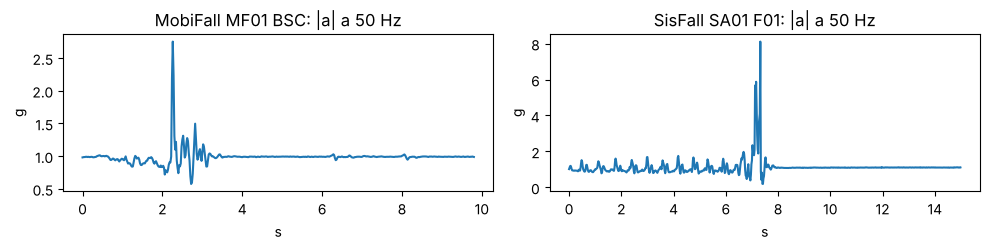

In [6]:
def para_fs(acc, fs_in, fs_out=FS):
    if fs_in == fs_out: out = acc.copy()
    else:
        fr = Fraction(int(fs_out), int(fs_in)).limit_denominator(1000)
        out = resample_poly(acc, fr.numerator, fr.denominator, axis=0, padtype='line')
    return np.clip(out, -CLIP_G, CLIP_G) if CLIP_G else out

def preprocessar(trials):
    out = []
    for t in trials:
        r = FS / t.fs; acc = para_fs(t.acc, t.fs)
        on = None if t.onset is None else int(round(t.onset * r))
        im = None if t.impact is None else int(round(t.impact * r))
        if t.is_fall and im is None:            # sem rótulo: intervalo aproximado pelo pico
            im = int(np.argmax(np.linalg.norm(acc, axis=1))); on = max(0, im - int(QUEDA_ANTES_PICO_S * FS))
        out.append(Trial(t.dataset, t.subject, t.group, t.activity, t.rep, t.is_fall, float(FS), acc, on, im, t.rotulo_real))
    return out

DADOS = {b: preprocessar(BRUTO[b]) for b in bases_usadas}
del BRUTO

UP = {}
for b, tr in DADOS.items():
    for s in sorted({t.subject for t in tr}):
        v = np.array([t.acc[:FS].mean(0) for t in tr if t.subject == s]); v /= np.linalg.norm(v, axis=1, keepdims=True)
        m = np.median(v, axis=0); UP[(b, s)] = m / np.linalg.norm(m)

fig, ax = plt.subplots(1, len(DADOS), figsize=(5 * len(DADOS), 2.6))
for a, (b, tr) in zip(np.atleast_1d(ax), DADOS.items()):
    t = next(t for t in tr if t.is_fall); a.plot(np.arange(len(t.acc)) / FS, np.linalg.norm(t.acc, axis=1))
    a.set_title(f'{b} {t.subject} {t.activity}: |a| a 50 Hz'); a.set_xlabel('s'); a.set_ylabel('g')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'fig_exemplos_sinal.png', dpi=150); plt.show()

## 5. Algoritmos de limiar

Os três olham o **formato da série temporal**, em três fases:
1. **Queda livre:** a magnitude cai abaixo de cerca de 0,6 g.
2. **Impacto:** em seguida vem um pico acima de 2 a 3 g.
3. **Postura ou repouso:** a pessoa fica deitada ou parada.

Cada função recebe a aceleração a 50 Hz e devolve a lista de alarmes.

### 5.1 Kangas et al. 2008, variante 2
- **Início da queda:** `SV_TOT` cai abaixo de 0,6 g.
- **Impacto:** em até 1 s, basta **um** destes quatro:
  - `SV_TOT ≥ 2,0 g`;
  - `SV_D ≥ 1,7 g`;
  - `SV_MaxMin ≥ 2,0 g`;
  - `Z2 ≥ 1,5 g`.
- **Postura:** 2 s depois do impacto, a vertical do sinal passa-baixa (média de 0,4 s) fica ≤ 0,5 g.
- **Filtros:** Butterworth de 2ª ordem, corte em 0,25 Hz.

In [7]:
def _iir(x, b, a):
    zi = lfilter_zi(b, a)
    return np.column_stack([lfilter(b, a, x[:, k], zi=zi * x[0, k])[0] for k in range(3)])

def _pad_fim(acc):
    n = int(PAD_FIM_S * FS)
    return np.vstack([acc, np.repeat(acc[-1:], n, 0)]) if n else acc

KANGAS_PUB = dict(inicio=0.6, svtot=2.0, svd=1.7, maxmin=2.0, z2=1.5,
                  jan_impacto=1.0, atraso_postura=2.0, jan_postura=0.4, deitado=0.5, refratario=10.0)

def kangas_features(acc, up):
    acc = _pad_fim(acc)
    bl, al = butter(2, 0.25, btype='low', fs=FS)
    bh, ah = butter(2, 0.25, btype='high', fs=FS)
    L, H = _iir(acc, bl, al), _iir(acc, bh, ah)
    svtot, svd = np.linalg.norm(acc, axis=1), np.linalg.norm(H, axis=1)
    w = max(1, int(round(0.1 * FS)))
    pad = np.vstack([np.repeat(acc[:1], w - 1, 0), acc])
    sw = np.lib.stride_tricks.sliding_window_view(pad, w, axis=0)
    svmm = np.linalg.norm(sw.max(-1) - sw.min(-1), axis=1)
    z2 = (svtot ** 2 - svd ** 2 - 1.0) / 2.0
    return dict(svtot=svtot, svd=svd, svmm=svmm, z2=z2, vert=L @ up)

def kangas_detect(f, p=KANGAS_PUB):
    sv, n = f['svtot'], len(f['svtot'])
    hit = (sv >= p['svtot']) | (f['svd'] >= p['svd']) | (f['svmm'] >= p['maxmin']) | (f['z2'] >= p['z2'])
    W, D, P = int(round(p['jan_impacto'] * FS)), int(round(p['atraso_postura'] * FS)), int(round(p['jan_postura'] * FS))
    ft = it = -1; ult = -10 ** 9; alarmes = []
    for i in range(1, n):
        if ft > -1: ft -= 1
        if it > -1: it -= 1
        if sv[i - 1] >= p['inicio'] > sv[i]:
            ft = W
        if ft > -1 and hit[i]:
            it = D
        if it == 0:
            if f['vert'][max(0, i - P + 1): i + 1].mean() <= p['deitado'] and (i - ult) / FS >= p['refratario']:
                alarmes.append(i); ult = i
    return alarmes

### 5.2 Bourke et al. 2010, "Bourke3"
- **Limiares de magnitude:** LFT = 0,65 g; UFT = 2,8 g.
- **Bordas de tempo:** descida ≤ 600 ms; subida ≤ 350 ms.
- **Velocidade vertical:** ≤ −0,7 m/s.
- **Postura:** entre t+1 s e t+3 s, ângulo com a vertical > 60° em mais de 75% do tempo.
- **SUPOSIÇÕES:** o início da integração da velocidade e a média móvel de 0,5 s para estimar a gravidade.

In [8]:
BOURKE_PUB = dict(lft=0.65, uft=2.8, tfe=0.600, tre=0.350, v_th=-0.7, post0=1.0, post1=3.0,
                  angulo=60.0, frac=0.75, lookback=1.0, jan_grav=0.5, usar_bordas=True)

def bourke_features(acc, up, p=BOURKE_PUB):
    acc = _pad_fim(acc)
    n = len(acc); w = max(1, int(round(p['jan_grav'] * FS)))
    cs = np.vstack([np.zeros((1, 3)), np.cumsum(acc, 0)])
    idx = np.arange(n); lo = np.maximum(0, idx - w + 1)
    g = (cs[idx + 1] - cs[lo]) / (idx + 1 - lo)[:, None]
    cosang = (g @ up) / np.maximum(np.linalg.norm(g, axis=1), 1e-9)
    return dict(sv=np.linalg.norm(acc, axis=1), theta=np.degrees(np.arccos(np.clip(cosang, -1, 1))))

def _ultimo(mask_idx, ate, desde=0):
    c = mask_idx[(mask_idx < ate) & (mask_idx >= desde)]
    return int(c[-1]) if len(c) else None

def bourke_detect(f, p=BOURKE_PUB):
    sv, th, n = f['sv'], f['theta'], len(f['sv'])
    abaixo = sv < p['lft']
    sobe = np.where(abaixo[:-1] & ~abaixo[1:])[0] + 1        # sv[j-1] < LFT <= sv[j]
    desce = np.where(~abaixo[:-1] & abaixo[1:])[0] + 1       # sv[j-1] >= LFT > sv[j]
    b1 = sv < 1.0
    desce1g = np.where(~b1[:-1] & b1[1:])[0] + 1
    P0, P1 = int(p['post0'] * FS), int(p['post1'] * FS)
    alarmes, pendente, bloq = [], None, 0
    for i in range(1, n):
        if pendente is not None and i >= pendente + P1:
            jan = th[pendente + P0: pendente + P1 + 1]
            if len(jan) and (jan > p['angulo']).mean() > p['frac']:
                alarmes.append(pendente)
            pendente = None
        if pendente is None and i > bloq and sv[i - 1] <= p['uft'] < sv[i]:
            ti = i
            tup = _ultimo(sobe, ti)
            tdown = _ultimo(desce, (tup + 1) if tup is not None else ti)
            if p['usar_bordas']:
                ok_borda = (tup is not None and tdown is not None and
                            (ti - tdown) / FS <= p['tfe'] and (ti - tup) / FS <= p['tre'])
            else:
                ok_borda = True
            lim = max(0, ti - int(p['lookback'] * FS))
            ancora = tdown if tdown is not None else ti
            s = _ultimo(desce1g, ancora + 1, desde=lim)
            s = lim if s is None else s
            v = np.cumsum((sv[s: ti + 1] - 1.0) * G0 / FS)
            ok_vel = len(v) > 0 and min(0.0, v.min()) <= p['v_th']
            if ok_borda and ok_vel:
                pendente, bloq = ti, ti + P1
            else:
                bloq = ti + int(0.5 * FS)
    return alarmes

### 5.3 PIPTO (Moutsis et al. 2023): código original dos autores
- O notebook baixa e chama `fall_detection` do repositório dos autores, sem modificar nada.
- **Entrada:** magnitude em m/s² e tempo em segundos, como nos scripts deles.
- **Limitação para o celular:** o limiar alto usa a **média da gravação inteira**, então só funciona depois do fato, com o arquivo completo.
- **Sem licença declarada:** por isso o código não é copiado para o nosso repositório.

In [9]:
PIPTO_DIR = VENDOR_DIR / 'pipto'
pipto_fall_detection = None
try:
    if not (PIPTO_DIR / 'python' / 'def_fall.py').exists():
        VENDOR_DIR.mkdir(exist_ok=True)
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/smoutsis/fall_detection_through_acceleration_data',
                        str(PIPTO_DIR)], check=True, capture_output=True)
    sys.path.insert(0, str(PIPTO_DIR / 'python'))
    from def_fall import fall_detection as pipto_fall_detection
    print('PIPTO carregado de', PIPTO_DIR)
except Exception as e:
    print('⚠️ PIPTO indisponível:', e)

PIPTO_ERROS = []
def pipto_detect(acc, nome=''):
    v = np.linalg.norm(acc, axis=1) * 9.807
    df = pd.DataFrame({'time': np.arange(len(v)) / FS, 'v': v})
    try:
        res = pipto_fall_detection(df, len(df), FS)
    except Exception as e:
        PIPTO_ERROS.append((nome, repr(e))); return []
    return [int(round(r[1] * FS / 100)) for r in res]

PIPTO carregado de /tmp/claude-0/-home-user-Mova-unama/a0f81b41-4052-5333-a97e-be984549fbe1/scratchpad/run_real/vendor/pipto


### 5.4 Rodar os limiares com os parâmetros publicados, em todas as bases

In [10]:
CACHE = {}
def _feats(t):
    if id(t) not in CACHE:
        up = UP[(t.dataset, t.subject)]
        CACHE[id(t)] = (kangas_features(t.acc, up), bourke_features(t.acc, up))
    return CACHE[id(t)]

def _linha(t, **kw):
    return dict(dataset=t.dataset, subject=t.subject, group=t.group, activity=t.activity, rep=t.rep,
                is_fall=t.is_fall, dur_s=len(t.acc) / FS, **kw)

def pred_limiar(trials, alg, p):
    rows = []
    for t in trials:
        fk, fb = _feats(t)
        n = len(kangas_detect(fk, p)) if alg == 'Kangas' else len(bourke_detect(fb, p))
        rows.append(_linha(t, n_alarmes=n))
    return pd.DataFrame(rows)

t0 = time.time()
PRED_PUB = []
for b, tr in DADOS.items():
    PRED_PUB.append(pred_limiar(tr, 'Kangas', KANGAS_PUB).assign(metodo='Kangas (publicado)'))
    PRED_PUB.append(pred_limiar(tr, 'Bourke3', BOURKE_PUB).assign(metodo='Bourke3 (publicado)'))
    if pipto_fall_detection is not None:
        PRED_PUB.append(pd.DataFrame([_linha(t, n_alarmes=len(pipto_detect(t.acc, f'{t.subject}_{t.activity}_{t.rep}')))
                                      for t in tr]).assign(metodo='PIPTO (publicado)'))
    print(b, 'ok', f'{time.time()-t0:.0f} s')
PRED_PUB = pd.concat(PRED_PUB, ignore_index=True)
print('erros internos do PIPTO:', len(PIPTO_ERROS), PIPTO_ERROS[:3])

MobiFall ok 51 s


SisFall ok 408 s
erros internos do PIPTO: 0 []


## 6. Métricas (iguais para todos)
- **Por tentativa:**
  - tentativa de queda = acerto (VP) se houver ≥ 1 alarme;
  - tentativa de ADL = falso positivo (FP) se houver ≥ 1 alarme.
- **Medidas:** SE, SP, precisão, F1 e acurácia, com IC de Wilson.
- **Alarmes falsos por hora:** total de alarmes nas tentativas de ADL ÷ horas de ADL.
- **Δ = métrica na base de treino − métrica na base de teste**, com IC 95% por bootstrap de sujeitos (sorteados separadamente em cada base).

In [11]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

def metricas(df):
    al = df.n_alarmes > 0
    tp = int((df.is_fall & al).sum()); fn = int((df.is_fall & ~al).sum())
    fp = int((~df.is_fall & al).sum()); tn = int((~df.is_fall & ~al).sum())
    se = tp / (tp + fn) if tp + fn else np.nan; sp = tn / (tn + fp) if tn + fp else np.nan
    pr = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * pr * se / (pr + se) if (tp > 0) else 0.0
    adl = df[~df.is_fall]
    fah = adl.n_alarmes.sum() / (adl.dur_s.sum() / 3600) if len(adl) else np.nan
    return dict(SE=se, SP=sp, Prec=pr, F1=f1, Acc=(tp + tn) / max(1, len(df)), FA_h=fah,
                SE_IC=wilson(tp, tp + fn), SP_IC=wilson(tn, tn + fp), TP=tp, FN=fn, FP=fp, TN=tn)

def _contagens(df):
    al = df.n_alarmes > 0
    c = pd.DataFrame({'tp': df.is_fall & al, 'fn': df.is_fall & ~al, 'fp': ~df.is_fall & al, 'tn': ~df.is_fall & ~al})
    return c.groupby(df.subject.values).sum().to_numpy(float)

def _metr_cont(c, metrica):
    tp, fn, fp, tn = c
    se = tp / (tp + fn) if tp + fn else np.nan; sp = tn / (tn + fp) if tn + fp else np.nan
    pr = tp / (tp + fp) if tp + fp else np.nan
    return {'SE': se, 'SP': sp, 'F1': (2 * pr * se / (pr + se) if tp > 0 else 0.0)}[metrica]

def delta_ic(df_a, df_b, metrica='F1', B=B_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); ca, cb = _contagens(df_a), _contagens(df_b)
    ds = [_metr_cont(ca[rng.integers(0, len(ca), len(ca))].sum(0), metrica) - _metr_cont(cb[rng.integers(0, len(cb), len(cb))].sum(0), metrica)
          for _ in range(B)]
    return np.nanpercentile(ds, [2.5, 97.5])

def tabela(pred, base_a, base_b):
    linhas = []
    for m, d in pred.groupby('metodo', sort=False):
        a, b = d[d.dataset == base_a], d[d.dataset == base_b]
        if a.empty or b.empty: continue
        ma, mb = metricas(a), metricas(b)
        lo, hi = delta_ic(a, b, 'F1')
        linhas.append({'Método': m,
                       f'{base_a} SE': ma['SE'], f'{base_a} SP': ma['SP'], f'{base_a} F1': ma['F1'], f'{base_a} FA/h': ma['FA_h'],
                       f'{base_b} SE': mb['SE'], f'{base_b} SP': mb['SP'], f'{base_b} F1': mb['F1'], f'{base_b} FA/h': mb['FA_h'],
                       'ΔF1': ma['F1'] - mb['F1'], 'ΔF1 IC95% inf': lo, 'ΔF1 IC95% sup': hi,
                       'ΔSE': ma['SE'] - mb['SE'], 'ΔSP': ma['SP'] - mb['SP']})
    return pd.DataFrame(linhas)

def por_base(pred):
    return pd.DataFrame([dict(Método=m, Base=b, **{k: v for k, v in metricas(d).items() if not k.endswith('_IC')},
                              SE_IC=metricas(d)['SE_IC'], SP_IC=metricas(d)['SP_IC'])
                         for (m, b), d in pred.groupby(['metodo', 'dataset'], sort=False)])

display(por_base(PRED_PUB).round(3))

,Método,Base,SE,SP,Prec,F1,Acc,FA_h,TP,FN,FP,TN,SE_IC,SP_IC
0,Kangas (publicado),MobiFall,0.896,0.904,0.887,0.891,0.900,13.149,258,30,33,309,"(0.8551898843088314, 0.9260558325457914)","(0.8675863366788946, 0.9304668761214164)"
1,Bourke3 (publicado),MobiFall,0.090,0.985,0.839,0.163,0.576,5.180,26,262,5,337,"(0.06235201809567117, 0.12899013463375467)","(0.966237442236782, 0.9937396108418529)"
2,PIPTO (publicado),MobiFall,0.045,1.000,1.000,0.086,0.563,0.000,13,275,0,342,"(0.02656610510554363, 0.07568662377203927)","(0.9888920245569071, 1.0)"
3,Kangas (publicado),SisFall,0.935,0.974,0.959,0.947,0.958,4.846,1630,114,69,2583,"(0.9220505324490168, 0.9453049533112489)","(0.9672032439299124, 0.9793893540623776)"
4,Bourke3 (publicado),SisFall,0.609,0.997,0.992,0.755,0.843,0.632,1062,682,9,2643,"(0.5858265160412339, 0.6315844896242682)","(0.993562459288024, 0.9982135562695303)"
5,PIPTO (publicado),SisFall,0.813,0.882,0.820,0.816,0.855,21.911,1418,326,312,2340,"(0.7940953149709828, 0.8306752592046176)","(0.8695337192392293, 0.8940660376137396)"


## 7. Limiares reajustados na base de treino
O ML é treinado na base de treino. Para a comparação ser justa, os limiares também são reajustados nela:
1. **Grade de valores:**
   - Kangas: fator de escala nos 4 limiares de impacto × limiar de início da queda;
   - Bourke3: UFT × LFT.
2. **Escolha:** o par com maior F1.
3. **Desempenho "dentro da base":** validação cruzada por sujeito.
4. **Teste na outra base:** com os limiares escolhidos em toda a base de treino.

O PIPTO entra só com os parâmetros publicados, porque ajustá-lo exigiria editar o código dos autores.

In [12]:
GRADE = {'Kangas': [dict(KANGAS_PUB, inicio=i, svtot=2.0 * s, svd=1.7 * s, maxmin=2.0 * s, z2=1.5 * s)
                    for s in (0.6, 0.8, 1.0, 1.2, 1.4, 1.7, 2.0) for i in (0.4, 0.5, 0.6, 0.7, 0.8)],
         'Bourke3': [dict(BOURKE_PUB, uft=u, lft=l) for u in (1.8, 2.2, 2.6, 2.8, 3.2, 3.6, 4.0) for l in (0.5, 0.65, 0.8)]}

def folds_por_sujeito(trials, k, seed=SEED):
    subs = sorted({t.subject for t in trials})
    return [set(f) for f in np.array_split(np.random.default_rng(seed).permutation(subs), min(k, len(subs)))]

MATRIZ = {}   # (base, alg) -> matriz [ponto da grade, tentativa] com o nº de alarmes (calculada uma vez só)
def matriz_grade(base, alg):
    if (base, alg) not in MATRIZ:
        MATRIZ[(base, alg)] = np.array([pred_limiar(DADOS[base], alg, p).n_alarmes.to_numpy() for p in GRADE[alg]])
    return MATRIZ[(base, alg)]

def _f1_vetor(n_alarmes, is_fall):
    al = n_alarmes > 0; tp = (al & is_fall).sum(); fp = (al & ~is_fall).sum(); fn = (~al & is_fall).sum()
    return 0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn)

def escolher(M, mask, is_fall):
    f1s = [_f1_vetor(M[g, mask], is_fall[mask]) for g in range(len(M))]
    return int(np.argmax(f1s)), max(f1s)

PRED_AJ, PARAMS_AJ = {}, {}
for (ba, bb) in DIRECOES:
    t0 = time.time(); lst = []
    tr_a = DADOS[ba]; subj = np.array([t.subject for t in tr_a]); queda = np.array([t.is_fall for t in tr_a])
    for alg in ('Kangas', 'Bourke3'):
        M = matriz_grade(ba, alg)
        for teste in folds_por_sujeito(tr_a, N_FOLDS):
            te = np.isin(subj, list(teste)); g, _ = escolher(M, ~te, queda)
            lst.append(pd.DataFrame([_linha(t, n_alarmes=int(M[g, i])) for i, t in enumerate(tr_a) if te[i]]).assign(metodo=f'{alg} (ajustado)'))
        g, f1 = escolher(M, np.ones(len(tr_a), bool), queda); p = GRADE[alg][g]; PARAMS_AJ[(ba, alg)] = p
        lst.append(pred_limiar(DADOS[bb], alg, p).assign(metodo=f'{alg} (ajustado)'))
        print(f'[{ba}→{bb}] {alg}: escolhido em toda a {ba} (F1={f1:.3f}):',
              {k: round(v, 3) for k, v in p.items() if k in ('inicio', 'svtot', 'uft', 'lft')}, f'({time.time()-t0:.0f} s)')
    PRED_AJ[(ba, bb)] = pd.concat(lst, ignore_index=True)

[SisFall→MobiFall] Kangas: escolhido em toda a SisFall (F1=0.967): {'inicio': 0.8, 'svtot': 2.0} (56 s)


[SisFall→MobiFall] Bourke3: escolhido em toda a SisFall (F1=0.770): {'lft': 0.65, 'uft': 1.8} (88 s)


[MobiFall→SisFall] Kangas: escolhido em toda a MobiFall (F1=0.924): {'inicio': 0.8, 'svtot': 2.0} (10 s)


[MobiFall→SisFall] Bourke3: escolhido em toda a MobiFall (F1=0.566): {'lft': 0.8, 'uft': 1.8} (16 s)


## 8. CNN-LSTM de Duan et al. (2026): reimplementação

### Arquitetura (Tabela 1 do artigo)
| Camada | Saída | Parâmetros |
|---|---|---|
| Entrada (4 s × [ax, ay, az, RMS]) | (200, 4) | 0 |
| Conv2D por canal (×4), 16 filtros | (24, 1, 16) | 544 × 4 |
| Conv2D, 32 filtros, núcleo (4, 3) | (21, 2, 32) | 6.176 |
| LSTM 32 → LSTM 16 | | 8.320 + 3.136 |
| Densa 64 → 8 → 2 | | 1.626 |
| **Total** | | **21.434** |

### Inconsistência na Tabela 1
A Tabela 1 diz núcleo (8, 1) na primeira convolução. Mas o núcleo **(33, 1) com passo 7** é o único que reproduz ao mesmo tempo a saída (24, 1, 16), os 544 parâmetros e o total de 21.434. Usamos essa versão.

### Suposições
- ativação ReLU;
- tamanho do lote = 64.

### Treino (como no artigo)
- janelas de 4 s com passo de 2 s, z-score;
- janela é "queda" se cobre ≥ 50% do intervalo da queda;
- otimizador Adam com taxa 0,001, 25 épocas, pesos de classe {ADL: 0,8; queda: 0,2}.

### Avaliação
- **Por tentativa:** queda se houver ≥ k janelas positivas seguidas (k = 2 como no artigo, e k = 1).
- **Normalização z-score de duas formas:**
  - `z treino`: estatísticas da base de treino. É a forma justa.
  - `z por base`: cada base com as suas, como no artigo.

### Experimento extra: `CNN-LSTM rot`
É a mesma rede, treinada com cópias das janelas **giradas em 3D aleatoriamente**. Serve para testar se a perda entre bases vem da orientação do sensor.

In [13]:
import tensorflow as tf
from tensorflow.keras import layers, Model

JAN, PASSO = int(JANELA_S * FS), int(PASSO_S * FS)

def construir_cnn_lstm():
    inp = layers.Input((JAN, 4))
    x4 = layers.Reshape((JAN, 4, 1))(inp)
    ramos = [layers.Conv2D(16, (33, 1), strides=(7, 1), activation='relu')(
                 layers.Cropping2D(((0, 0), (c, 3 - c)))(x4)) for c in range(4)]
    x = layers.Concatenate(axis=2)(ramos)
    x = layers.Conv2D(32, (4, 3), activation='relu')(x)
    x = layers.Reshape((-1, 32))(x)
    x = layers.LSTM(32, return_sequences=True)(x)
    x = layers.LSTM(16)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dense(8, activation='relu')(x)
    out = layers.Dense(2, activation='softmax')(x)
    m = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    return m

_modelo_teste = construir_cnn_lstm()
assert _modelo_teste.count_params() == 21434, _modelo_teste.count_params()
print('Parâmetros:', _modelo_teste.count_params(), '(o artigo informa 21.434) ✓')

I0000 00:00:1791860958.103482   10805 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791860959.719775   10805 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Parâmetros: 21434 (o artigo informa 21.434) ✓


In [14]:
JAN, PASSO = int(JANELA_S * FS), int(PASSO_S * FS)

def janelas(t):
    x = np.hstack([t.acc, np.linalg.norm(t.acc, axis=1, keepdims=True)])
    if len(x) < JAN: x = np.vstack([x, np.repeat(x[-1:], JAN - len(x), 0)])
    ini = np.arange(0, len(x) - JAN + 1, PASSO)
    X = np.stack([x[s:s + JAN] for s in ini]).astype(np.float32)
    y = np.zeros(len(ini), dtype=np.int64)
    if t.is_fall and t.onset is not None:
        a, b = t.onset, t.impact + int(0.5 * FS); dur = max(1, b - a)
        y = (np.clip(np.minimum(ini + JAN, b) - np.maximum(ini, a), 0, None) >= 0.5 * dur).astype(np.int64)
    return X, y

def montar(trials):
    Xs, ys, tid = [], [], []
    for k, t in enumerate(trials):
        X, y = janelas(t); Xs.append(X); ys.append(y); tid.append(np.full(len(y), k))
    return np.concatenate(Xs), np.concatenate(ys), np.concatenate(tid)

def zstats(X): return X.reshape(-1, 4).mean(0), X.reshape(-1, 4).std(0) + 1e-8

def rotacoes_aleatorias(n, rng):
    q = rng.normal(size=(n, 4)); q /= np.linalg.norm(q, axis=1, keepdims=True)
    w, x, y, z = q.T
    return np.stack([np.stack([1-2*(y*y+z*z), 2*(x*y-z*w), 2*(x*z+y*w)], -1),
                     np.stack([2*(x*y+z*w), 1-2*(x*x+z*z), 2*(y*z-x*w)], -1),
                     np.stack([2*(x*z-y*w), 2*(y*z+x*w), 1-2*(x*x+y*y)], -1)], 1)   # (n,3,3)

def aumentar_rotacao(X, y, rng):
    R = rotacoes_aleatorias(len(X), rng)
    Xr = X.copy(); Xr[:, :, :3] = np.einsum('nij,ntj->nti', R, X[:, :, :3])
    return np.concatenate([X, Xr]), np.concatenate([y, y])

def treinar(X, y, seed):
    tf.keras.utils.set_random_seed(seed)
    m = construir_cnn_lstm()
    m.fit(X, tf.keras.utils.to_categorical(y, 2), epochs=EPOCAS, batch_size=BATCH, class_weight=PESO_CLASSE, verbose=0)
    return m

def maior_sequencia(pos):
    run = best = 0
    for v in pos:
        run = run + 1 if v else 0; best = max(best, run)
    return best

def linhas_tentativa(trials, prob, tid, nome):
    rows = []
    for k_trial, t in enumerate(trials):
        seq = maior_sequencia(prob[tid == k_trial] >= 0.5)
        for k in K_JANELAS:
            rows.append(_linha(t, n_alarmes=int(seq >= k), metodo=f'{nome} k={k}'))
    return rows

def janela_metr(prob, y):
    p = prob >= 0.5
    return dict(acc=(p == y).mean(), rec=(p & (y == 1)).sum() / max(1, (y == 1).sum()), prec=(p & (y == 1)).sum() / max(1, p.sum()))

JAN_DADOS = {b: montar(tr) for b, tr in DADOS.items()}
for b, (X, y, _) in JAN_DADOS.items():
    print(f'{b}: {X.shape[0]} janelas, {int(y.sum())} de queda')

MobiFall: 4768 janelas, 408 de queda
SisFall: 33194 janelas, 3485 de queda


### 8.1 Dentro da base de treino (validação cruzada por sujeito) e entre bases
- **Dentro da base:** cada sujeito é testado por um modelo treinado sem ele (`N_FOLDS` partes); o z-score usa só o treino.
- **Entre bases:** `N_SEMENTES` modelos treinados com toda a base de treino, aplicados na outra base.
- Na tabela, a "decisão" de cada tentativa entre bases é a da **maioria das sementes**.

In [15]:
PRED_CNN, JANELA_RES, SEMENTE_RES = {}, [], []
for (ba, bb) in DIRECOES:
    t0 = time.time(); rows = []
    Xa, ya, ta = JAN_DADOS[ba]; Xb, yb, tb = JAN_DADOS[bb]
    sub_a = np.array([DADOS[ba][i].subject for i in ta])
    variantes = [('CNN-LSTM', False)] + ([('CNN-LSTM rot', True)] if AUMENTO_ROTACAO else [])
    for nome, rot in variantes:
        # --- dentro da base de treino ---
        for i_f, teste in enumerate(folds_por_sujeito(DADOS[ba], N_FOLDS)):
            te = np.isin(sub_a, list(teste)); tr = ~te
            mu, sd = zstats(Xa[tr]); Xtr, ytr = (Xa[tr] - mu) / sd, ya[tr]
            if rot: Xtr, ytr = aumentar_rotacao(Xa[tr], ya[tr], np.random.default_rng(SEED + i_f)); Xtr = (Xtr - mu) / sd
            m = treinar(Xtr, ytr, SEED + i_f)
            idx_tr = [i for i, t in enumerate(DADOS[ba]) if t.subject in teste]
            mapa = {g: j for j, g in enumerate(idx_tr)}
            prob = m.predict((Xa[te] - mu) / sd, verbose=0, batch_size=2048)[:, 1]
            JANELA_RES.append(dict(direcao=f'{ba}→{bb}', variante=nome, base=ba, fold=i_f, **janela_metr(prob, ya[te])))
            for zmodo in ('z treino', 'z por base'):
                rows += linhas_tentativa([DADOS[ba][g] for g in idx_tr], prob, np.array([mapa[g] for g in ta[te]]), f'{nome} [{zmodo}]')
            print(f'[{ba}→{bb}] {nome} fold {i_f+1}: acurácia por janela = {JANELA_RES[-1]["acc"]:.3f}  ({time.time()-t0:.0f} s)')
        # --- entre bases ---
        mu_a, sd_a = zstats(Xa); mu_b, sd_b = zstats(Xb)
        cruz = []
        for sem in range(N_SEMENTES):
            Xtr, ytr = (Xa, ya) if not rot else aumentar_rotacao(Xa, ya, np.random.default_rng(SEED + 100 + sem))
            m = treinar((Xtr - mu_a) / sd_a, ytr, SEED + 100 + sem)
            for zmodo, (mu, sd) in (('z treino', (mu_a, sd_a)), ('z por base', (mu_b, sd_b))):
                prob = m.predict((Xb - mu) / sd, verbose=0, batch_size=2048)[:, 1]
                JANELA_RES.append(dict(direcao=f'{ba}→{bb}', variante=f'{nome} [{zmodo}]', base=bb, fold=f'semente {sem}', **janela_metr(prob, yb)))
                lt = linhas_tentativa(DADOS[bb], prob, tb, f'{nome} [{zmodo}]')
                cruz += [dict(r, semente=sem) for r in lt]
            print(f'[{ba}→{bb}] {nome} semente {sem+1}/{N_SEMENTES} ok ({time.time()-t0:.0f} s)')
        cruz = pd.DataFrame(cruz)
        for (met, sem), d in cruz.groupby(['metodo', 'semente']):
            SEMENTE_RES.append(dict(direcao=f'{ba}→{bb}', metodo=met, semente=sem, **{k: v for k, v in metricas(d).items() if not k.endswith('_IC')}))
        maj = cruz.groupby(['dataset', 'subject', 'group', 'activity', 'rep', 'is_fall', 'dur_s', 'metodo'], as_index=False).n_alarmes.mean()
        maj['n_alarmes'] = (maj.n_alarmes >= 0.5).astype(int)
        rows += maj.to_dict('records')
    PRED_CNN[(ba, bb)] = pd.DataFrame(rows)
    PRED_CNN[(ba, bb)].to_csv(RESULTS_DIR / f'pred_cnn_{ba}_{bb}.csv', index=False)

JANELA_RES = pd.DataFrame(JANELA_RES); SEMENTE_RES = pd.DataFrame(SEMENTE_RES)
JANELA_RES.to_csv(RESULTS_DIR / 'cnn_metricas_por_janela.csv', index=False); SEMENTE_RES.to_csv(RESULTS_DIR / 'cnn_variacao_sementes.csv', index=False)
display(JANELA_RES.groupby(['direcao', 'variante', 'base'])[['acc', 'rec', 'prec']].mean().round(4))

[SisFall→MobiFall] CNN-LSTM fold 1: acurácia por janela = 0.994  (360 s)


[SisFall→MobiFall] CNN-LSTM fold 2: acurácia por janela = 0.991  (768 s)


[SisFall→MobiFall] CNN-LSTM fold 3: acurácia por janela = 0.990  (1144 s)


[SisFall→MobiFall] CNN-LSTM fold 4: acurácia por janela = 0.991  (1523 s)


[SisFall→MobiFall] CNN-LSTM fold 5: acurácia por janela = 0.986  (1920 s)


...

[MobiFall→SisFall] CNN-LSTM rot fold 5: acurácia por janela = 0.982  (1087 s)


[MobiFall→SisFall] CNN-LSTM rot semente 1/3 ok (1220 s)


[MobiFall→SisFall] CNN-LSTM rot semente 2/3 ok (1354 s)


[MobiFall→SisFall] CNN-LSTM rot semente 3/3 ok (1491 s)


acc     rec    prec
direcao          variante                  base                            
MobiFall→SisFall CNN-LSTM                  MobiFall  0.9570  0.7343  0.8447
                 CNN-LSTM [z por base]     SisFall   0.8475  0.0277  0.0686
                 CNN-LSTM [z treino]       SisFall   0.5109  0.6816  0.1437
                 CNN-LSTM rot              MobiFall  0.9800  0.8584  0.9266
                 CNN-LSTM rot [z por base] SisFall   0.9192  0.5366  0.6439
                 CNN-LSTM rot [z treino]   SisFall   0.9178  0.6061  0.6182
SisFall→MobiFall CNN-LSTM                  SisFall   0.9903  0.9304  0.9754
                 CNN-LSTM [z por base]     MobiFall  0.5849  0.0400  0.0095
                 CNN-LSTM [z treino]       MobiFall  0.6980  0.5057  0.1464
                 CNN-LSTM rot              SisFall   0.9905  0.9366  0.9709
                 CNN-LSTM rot [z por base] MobiFall  0.9448  0.4175  0.8918
                 CNN-LSTM rot [z treino]   MobiFall  0.9500  0.5686  0.7990

## 9. Resultado principal: quanto cada método perde de uma base para a outra?

In [16]:
TABELAS = {}
for (ba, bb) in DIRECOES:
    pred = pd.concat([PRED_PUB[PRED_PUB.dataset.isin([ba, bb])], PRED_AJ[(ba, bb)], PRED_CNN[(ba, bb)]], ignore_index=True)
    pred.to_csv(RESULTS_DIR / f'predicoes_{ba}_{bb}.csv', index=False)
    TAB = tabela(pred, ba, bb); TABELAS[(ba, bb)] = TAB
    TAB.to_csv(RESULTS_DIR / f'tabela_{ba}_{bb}.csv', index=False)
    print(f'\n=== {ba} (treino/ajuste) → {bb} (teste) ==='); display(TAB.round(3))


=== SisFall (treino/ajuste) → MobiFall (teste) ===


,Método,SisFall SE,SisFall SP,SisFall F1,SisFall FA/h,MobiFall SE,MobiFall SP,MobiFall F1,MobiFall FA/h,ΔF1,ΔF1 IC95% inf,ΔF1 IC95% sup,ΔSE,ΔSP
0,Kangas (publicado),0.935,0.974,0.947,4.846,0.896,0.904,0.891,13.149,0.056,0.012,0.100,0.039,0.070
1,Bourke3 (publicado),0.609,0.997,0.755,0.632,0.090,0.985,0.163,5.180,0.592,0.511,0.678,0.519,0.011
2,PIPTO (publicado),0.813,0.882,0.816,21.911,0.045,1.000,0.086,0.000,0.730,0.667,0.792,0.768,-0.118
3,Kangas (ajustado),0.967,0.974,0.964,4.776,0.969,0.892,0.924,14.743,0.040,0.003,0.080,-0.002,0.083
4,Bourke3 (ajustado),0.630,0.994,0.768,1.405,0.340,0.947,0.485,11.555,0.283,0.191,0.386,0.289,0.046
5,CNN-LSTM [z treino] k=2,0.878,0.998,0.934,0.281,0.156,0.728,0.211,37.057,0.723,0.637,0.800,0.722,0.270
6,CNN-LSTM [z treino] k=1,0.994,0.990,0.989,1.896,0.545,0.673,0.564,44.628,0.426,0.342,0.501,0.449,0.317
7,CNN-LSTM [z por base] k=2,0.878,0.998,0.934,0.281,0.000,0.632,0.000,50.206,0.934,0.920,0.947,0.878,0.367
8,CNN-LSTM [z por base] k=1,0.994,0.990,0.989,1.896,0.014,0.529,0.018,64.152,0.972,0.948,0.990,0.980,0.461
9,CNN-LSTM rot [z treino] k=2,0.894,0.999,0.943,0.211,0.153,0.994,0.263,0.797,0.680,0.589,0.776,0.741,0.005



=== MobiFall (treino/ajuste) → SisFall (teste) ===


,Método,MobiFall SE,MobiFall SP,MobiFall F1,MobiFall FA/h,SisFall SE,SisFall SP,SisFall F1,SisFall FA/h,ΔF1,ΔF1 IC95% inf,ΔF1 IC95% sup,ΔSE,ΔSP
0,Kangas (publicado),0.896,0.904,0.891,13.149,0.935,0.974,0.947,4.846,-0.056,-0.098,-0.008,-0.039,-0.070
1,Bourke3 (publicado),0.090,0.985,0.163,5.180,0.609,0.997,0.755,0.632,-0.592,-0.676,-0.501,-0.519,-0.011
2,PIPTO (publicado),0.045,1.000,0.086,0.000,0.813,0.882,0.816,21.911,-0.730,-0.787,-0.662,-0.768,0.118
3,Kangas (ajustado),0.969,0.892,0.924,14.743,0.980,0.969,0.967,5.829,-0.043,-0.083,-0.005,-0.011,-0.077
4,Bourke3 (ajustado),0.424,0.939,0.566,12.751,0.614,0.993,0.756,1.545,-0.190,-0.295,-0.078,-0.190,-0.054
5,CNN-LSTM [z treino] k=2,0.163,0.988,0.277,1.594,0.730,0.404,0.554,111.092,-0.277,-0.381,-0.154,-0.567,0.584
6,CNN-LSTM [z treino] k=1,0.938,0.927,0.926,9.962,0.968,0.202,0.609,148.756,0.317,0.250,0.382,-0.031,0.725
7,CNN-LSTM [z por base] k=2,0.163,0.988,0.277,1.594,0.014,0.954,0.026,8.589,0.251,0.141,0.368,0.149,0.034
8,CNN-LSTM [z por base] k=1,0.938,0.927,0.926,9.962,0.085,0.758,0.118,45.127,0.809,0.725,0.882,0.852,0.169
9,CNN-LSTM rot [z treino] k=2,0.333,1.000,0.500,0.000,0.325,0.904,0.442,17.811,0.058,-0.053,0.160,0.009,0.096


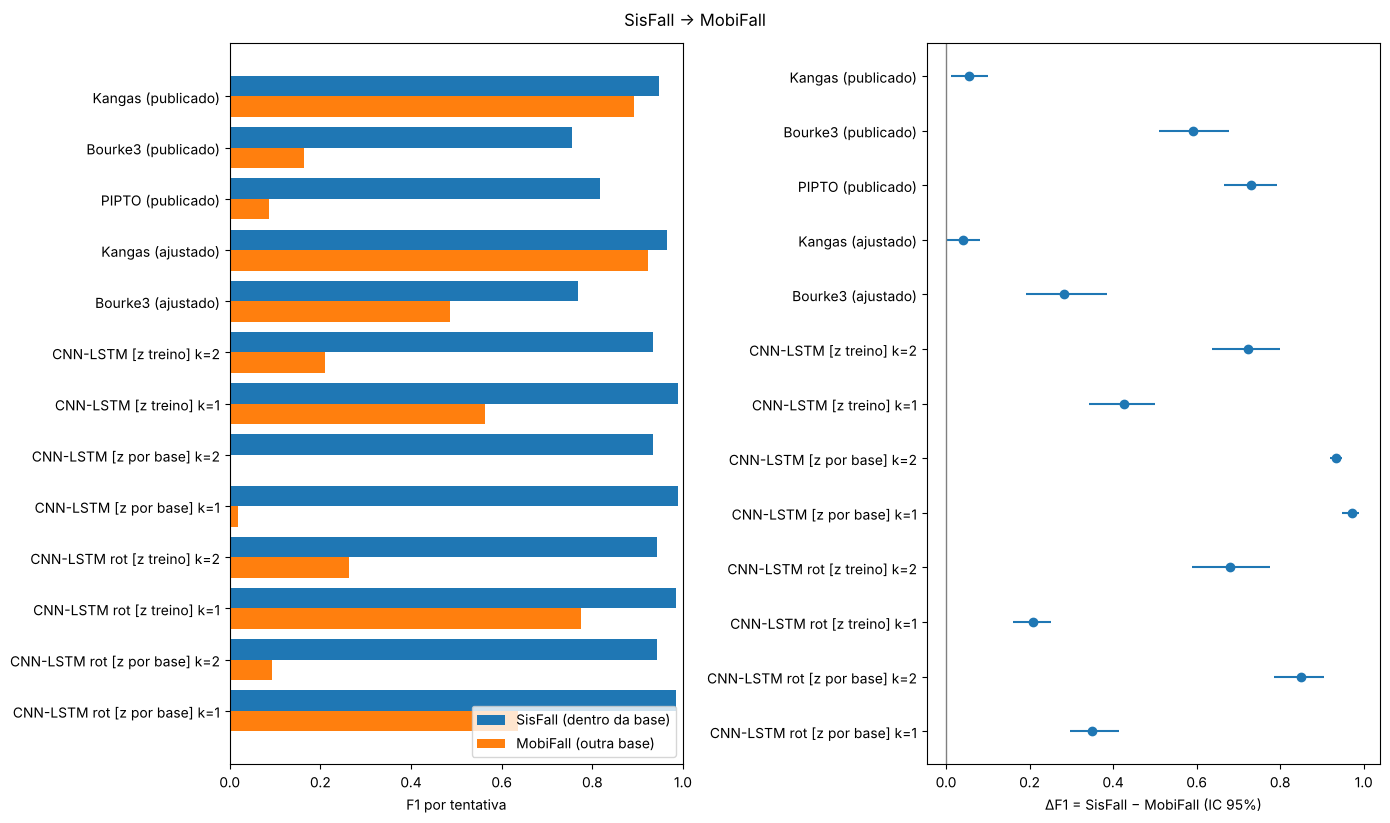

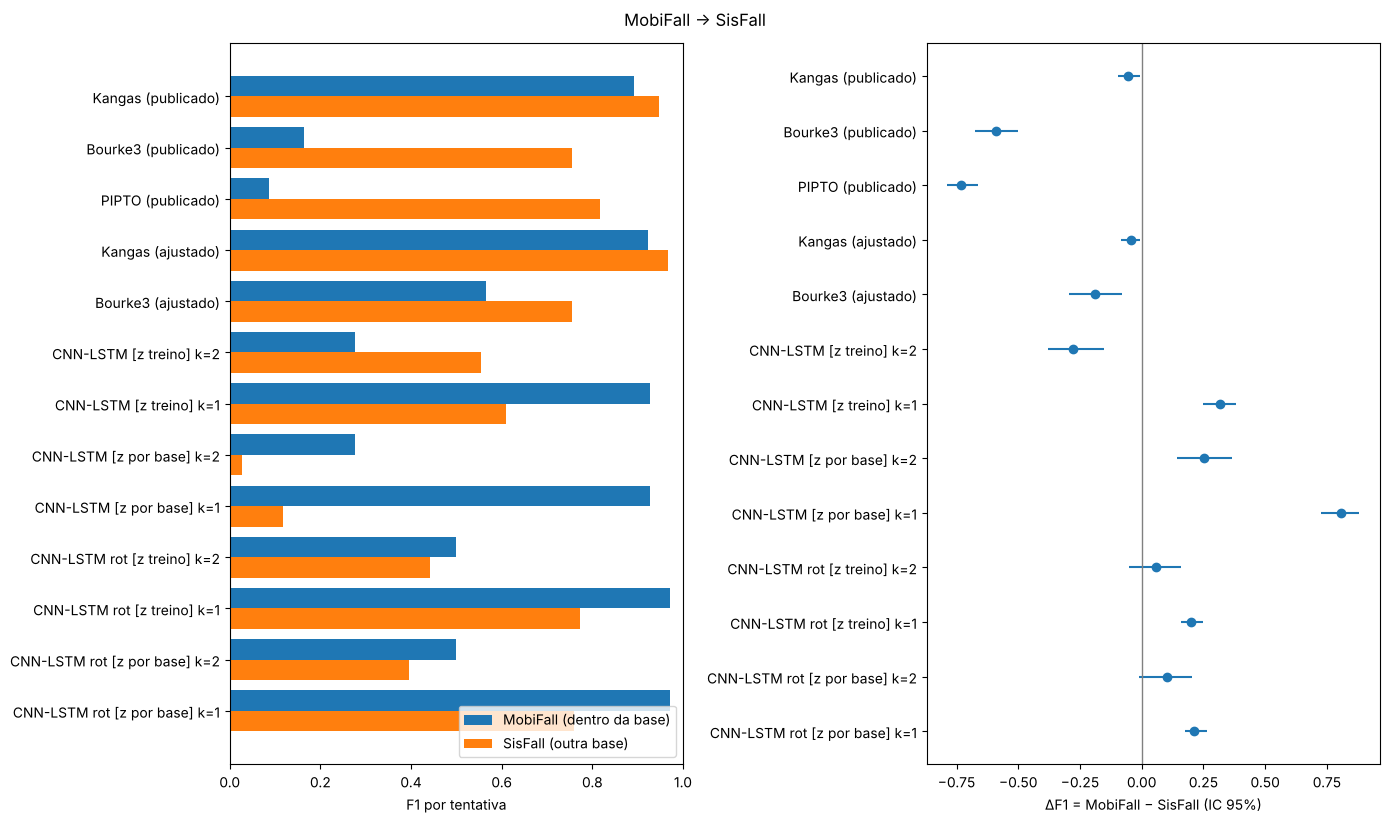

In [17]:
for (ba, bb), TAB in TABELAS.items():
    fig, ax = plt.subplots(1, 2, figsize=(14, 0.45 * len(TAB) + 2.5))
    y = np.arange(len(TAB))
    ax[0].barh(y - 0.2, TAB[f'{ba} F1'], 0.4, label=f'{ba} (dentro da base)')
    ax[0].barh(y + 0.2, TAB[f'{bb} F1'], 0.4, label=f'{bb} (outra base)')
    ax[0].set_yticks(y, TAB['Método']); ax[0].invert_yaxis(); ax[0].set_xlim(0, 1); ax[0].set_xlabel('F1 por tentativa'); ax[0].legend(loc='lower right')
    ax[1].errorbar(TAB['ΔF1'], y, xerr=[TAB['ΔF1'] - TAB['ΔF1 IC95% inf'], TAB['ΔF1 IC95% sup'] - TAB['ΔF1']], fmt='o')
    ax[1].axvline(0, color='gray', lw=1); ax[1].set_yticks(y, TAB['Método']); ax[1].invert_yaxis()
    ax[1].set_xlabel(f'ΔF1 = {ba} − {bb} (IC 95%)')
    fig.suptitle(f'{ba} → {bb}'); plt.tight_layout(); plt.savefig(RESULTS_DIR / f'fig_delta_{ba}_{bb}.png', dpi=150); plt.show()

## 10. Onde cada método erra
Para cada base de teste: a taxa de falso positivo por tipo de ADL e a taxa de queda perdida por tipo de queda. Na SisFall, a especificidade também sai separada entre jovens e idosos.

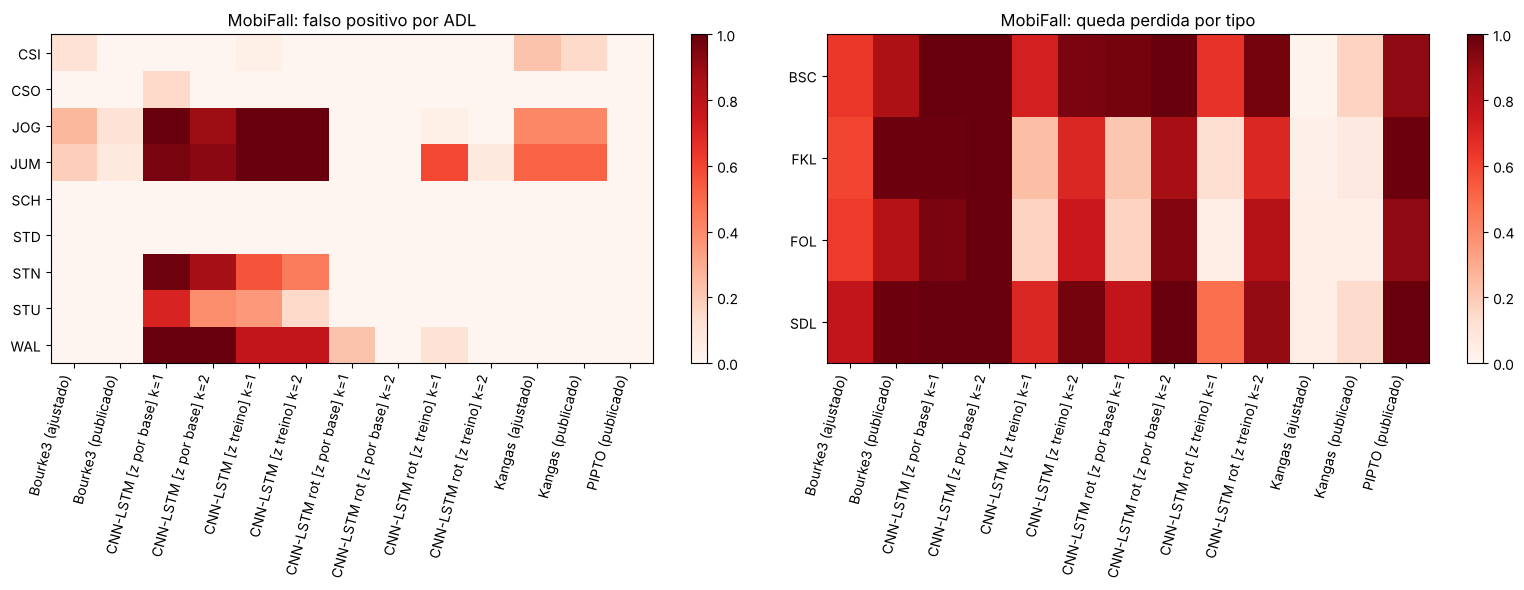

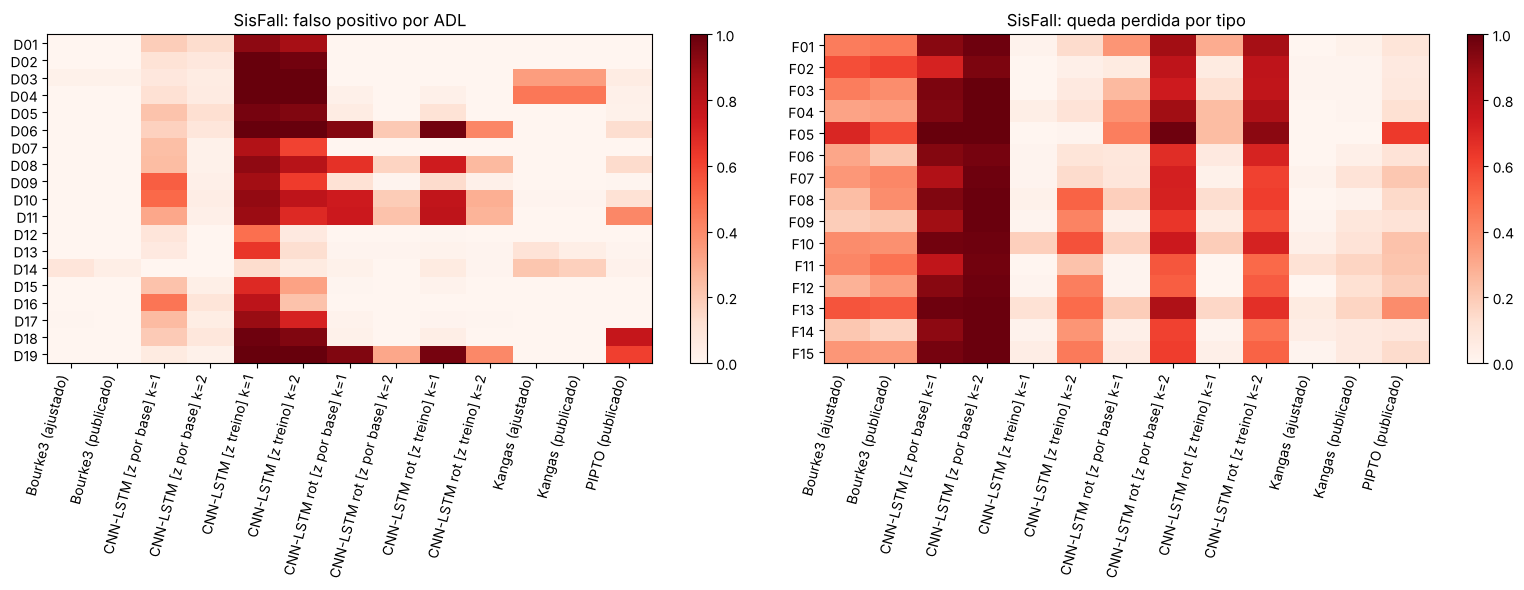

Especificidade na SisFall, jovens × idosos:


group,idoso,jovem
metodo,,
Bourke3 (ajustado),0.989,0.995
Bourke3 (publicado),0.998,0.996
CNN-LSTM [z por base] k=1,0.725,0.775
CNN-LSTM [z por base] k=2,0.950,0.956
CNN-LSTM [z treino] k=1,0.288,0.158
CNN-LSTM [z treino] k=2,0.545,0.332
CNN-LSTM rot [z por base] k=1,0.834,0.709
CNN-LSTM rot [z por base] k=2,0.969,0.919
CNN-LSTM rot [z treino] k=1,0.805,0.688


In [18]:
ERROS = {}
for (ba, bb) in DIRECOES:
    pred = pd.concat([PRED_PUB[PRED_PUB.dataset == bb], PRED_AJ[(ba, bb)], PRED_CNN[(ba, bb)]], ignore_index=True)
    d = pred[pred.dataset == bb].copy(); d['alarme'] = d.n_alarmes > 0
    fp = d[~d.is_fall].pivot_table(index='activity', columns='metodo', values='alarme', aggfunc='mean')
    fn = 1 - d[d.is_fall].pivot_table(index='activity', columns='metodo', values='alarme', aggfunc='mean')
    ERROS[(ba, bb)] = (fp, fn)
    fp.to_csv(RESULTS_DIR / f'fp_por_adl_{ba}_{bb}.csv'); fn.to_csv(RESULTS_DIR / f'fn_por_queda_{ba}_{bb}.csv')
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    for a, m_, tit in ((ax[0], fp, f'{bb}: falso positivo por ADL'), (ax[1], fn, f'{bb}: queda perdida por tipo')):
        im = a.imshow(m_.values, aspect='auto', cmap='Reds', vmin=0, vmax=1)
        a.set_yticks(range(len(m_)), m_.index); a.set_xticks(range(m_.shape[1]), m_.columns, rotation=75, ha='right'); a.set_title(tit)
        plt.colorbar(im, ax=a)
    plt.tight_layout(); plt.savefig(RESULTS_DIR / f'fig_erros_{ba}_{bb}.png', dpi=150); plt.show()
    if bb == 'SisFall':
        sp = d[~d.is_fall].groupby(['metodo', 'group']).alarme.apply(lambda a: 1 - a.mean()).unstack()
        sp.to_csv(RESULTS_DIR / f'sp_jovem_idoso_{ba}_{bb}.csv'); print('Especificidade na SisFall, jovens × idosos:'); display(sp.round(3))

In [19]:
# Salva um resumo em JSON (usado para o relatório)
resumo = dict(orientacao=ORIENT, pipto_erros=len(PIPTO_ERROS), params_ajustados={f'{k[0]}|{k[1]}': {kk: vv for kk, vv in v.items()}
              for k, v in PARAMS_AJ.items()}, config=dict(FS=FS, CLIP_G=CLIP_G, EPOCAS=EPOCAS, BATCH=BATCH, N_FOLDS=N_FOLDS,
              N_SEMENTES=N_SEMENTES, PESO_CLASSE=PESO_CLASSE, DIRECOES=DIRECOES))
(RESULTS_DIR / 'resumo.json').write_text(json.dumps(resumo, indent=2, ensure_ascii=False, default=str))
print('resultados em', RESULTS_DIR)

resultados em /tmp/claude-0/-home-user-Mova-unama/a0f81b41-4052-5333-a97e-be984549fbe1/scratchpad/run_real/results


## 11. Checklist antes de escrever o artigo
1. **Conferir no PDF original** os parâmetros de Kangas e Bourke3 que vieram de fontes secundárias.
2. **Declarar todas as `SUPOSIÇÃO`**, a correção do núcleo da 1ª convolução e a troca da KFall pela MobiFall, que não pôde ser obtida.
3. **Ameaças à validade:**
   - só há quedas simuladas por jovens;
   - os espelhos das bases não declaram licença e o da SisFall está incompleto;
   - os parâmetros do PIPTO foram desenvolvidos com a KFall e a MMsys;
   - a CNN foi reimplementada sem o código dos autores.
4. **Para reproduzir exatamente Duan et al.:** obtenha a KFall e rode a direção `('KFall', 'SisFall')`.